## Лабораторна робота №3: Знайомство з нейронними мережами
### ФБ-61мп Невмержицька Дар'я

### **Мета роботи:** Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання. Для побудови та навчання нейронних мереж використовуйте PyTorch.  
### Хід роботи: 

Імпорт необхідних бібліотек

In [ ]:

import os
import re
import io
import time
import copy
import random
import zipfile
import warnings
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import Dataset, TensorDataset, DataLoader, Subset
from torchvision import datasets, transforms, models

import gensim.downloader as api

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tqdm.auto import tqdm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DEVICE = device

print('PyTorch:', torch.__version__, '| Пристрій:', device)

PyTorch: 2.15.0+cpu | Device: cpu


1. Повнозв'язані нейронні мережі
Візьміть датасет, з яким ви працювали в лабораторній роботі №1. Побудуйте повнозв'язану нейронну мережу (MLP) для задачі класифікації. Навчіть модель на тренувальній вибірці та оцініть її якість на тестовій.
Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання моделі. Чи спостерігається перенавчання?
Порівняйте результати нейронної мережі з результатами класичних алгоритмів машинного навчання з Lab 1. Зробіть висновки.


1.1. Дані та цільова змінна

Класи: 0 = Missing (відсутній запис сповіщення), 1 = Alert Data (сповіщення присутнє).

In [ ]:
CSV_PATH='cybersecurity_attacks.csv'  
if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(f'Завантажте оригінальний файл Lab 1: {CSV_PATH}')
df=pd.read_csv(CSV_PATH)
features=['Source Port','Destination Port','Protocol','Packet Length','Packet Type',
          'Traffic Type','Malware Indicators','Anomaly Scores','Severity Level','Network Segment']
target='IDS/IPS Alerts'
missing=[c for c in features+[target] if c not in df.columns]
if missing: raise ValueError(f'Відсутні колонки: {missing}')
X=df[features].copy()
y=df[target].eq('Alert Data').astype(int)
print('Дані:',X.shape,'| Класи:',y.value_counts().sort_index().to_dict())
display(df[features+[target]].head())

Дані: (40000, 10) | Класи: {0: 20050, 1: 19950}


,Source Port,Destination Port,Protocol,Packet Length,Packet Type,Traffic Type,Malware Indicators,Anomaly Scores,Severity Level,Network Segment,IDS/IPS Alerts
0,31225,17616,ICMP,503,Data,HTTP,IoC Detected,28.67,Low,Segment A,NaN
1,17245,48166,ICMP,1174,Data,HTTP,IoC Detected,51.50,Low,Segment B,NaN
2,16811,53600,UDP,306,Control,HTTP,IoC Detected,87.42,Low,Segment C,Alert Data
3,20018,32534,UDP,385,Data,HTTP,NaN,15.79,Medium,Segment B,Alert Data
4,6131,26646,TCP,1462,Data,DNS,NaN,0.52,Low,Segment C,Alert Data


Використано Cyber Security Attacks із 40 000 записів і 10 ознак. Цільова змінна IDS/IPS Alerts містить два класи: Missing — 20 050 записів та Alert Data — 19 950. Класи майже збалансовані.

1.2. Train / validation / test і підготовка ознак

Спершу відокремлюємо тестову вибірку 30%, як у Lab 1. Із решти 70% відокремлюємо 20% для validation. Імпутація, стандартизація й One-Hot Encoding навчаються тільки на train, щоб уникнути витоку даних.

In [ ]:
X_train_all,X_test,y_train_all,y_test=train_test_split(X,y,test_size=0.30,random_state=SEED,stratify=y)
X_train,X_val,y_train,y_val=train_test_split(X_train_all,y_train_all,test_size=0.20,random_state=SEED,stratify=y_train_all)
numerical=['Source Port','Destination Port','Packet Length','Anomaly Scores']
categorical=['Protocol','Packet Type','Traffic Type','Malware Indicators','Severity Level','Network Segment']
try: encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError: encoder=OneHotEncoder(handle_unknown='ignore',sparse=False)
preprocessor=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),numerical),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value='Unknown')),('encoder',encoder)]),categorical)
])
Xtr=preprocessor.fit_transform(X_train).astype('float32')
Xva=preprocessor.transform(X_val).astype('float32')
Xte=preprocessor.transform(X_test).astype('float32')
print('Train:',Xtr.shape,'Validation:',Xva.shape,'Test:',Xte.shape)
print('Розподіл test:',y_test.value_counts().sort_index().to_dict())

Train: (22400, 20) Validation: (5600, 20) Test: (12000, 20)
Розподіл test: {0: 6015, 1: 5985}


Дані розділено на навчальну (22 400), валідаційну (5 600) і тестову (12 000) вибірки. Після передобробки кількість ознак збільшилася до 20 через кодування категоріальних значень.

1.3. Тензори й DataLoader

DataLoader подає дані невеликими пакетами (batch), що робить навчання ефективнішим.

In [24]:
def make_loader(a,b,batch_size=256,shuffle=False):
    ds=TensorDataset(torch.tensor(a,dtype=torch.float32),torch.tensor(np.asarray(b),dtype=torch.float32).view(-1,1))
    return DataLoader(ds,batch_size=batch_size,shuffle=shuffle)
train_loader=make_loader(Xtr,y_train,shuffle=True)
val_loader=make_loader(Xva,y_val)
test_loader=make_loader(Xte,y_test)
print('Batch size:',train_loader.batch_size,'| Batches:',len(train_loader))

Batch size: 256 | Batches: 88


Встановлено batch size = 256, тобто модель обробляє до 256 записів за один крок. Навчальна вибірка містить 88 пакетів.

1.4. Архітектура MLP

Linear — повнозв’язаний шар, ReLU — нелінійна активація, Dropout — регуляризація. Вихід — один logit; BCEWithLogitsLoss поєднує sigmoid і бінарну крос-ентропію чисельно стабільним способом.

In [25]:
class MLP(nn.Module):
    def __init__(self,input_dim):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(input_dim,64),nn.ReLU(),nn.Dropout(0.20),
            nn.Linear(64,32),nn.ReLU(),nn.Dropout(0.10),
            nn.Linear(32,1)
        )
    def forward(self,x): return self.net(x)
model=MLP(Xtr.shape[1]).to(device)
criterion=nn.BCEWithLogitsLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
print(model)
print('Кількість параметрів:',sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Кількість параметрів: 3457


Побудовано нейронну мережу з архітектурою 20 → 64 → 32 → 1, функціями активації ReLU та регуляризацією Dropout (0,2 і 0,1). Загальна кількість параметрів — 3 457.

1.5. Навчання MLP

На кожній епосі обчислюємо train loss, validation loss, train accuracy і validation accuracy. Модель навчається всі 20 епох без автоматичної зупинки. Для підсумкового тестування відновлюємо ваги епохи з найменшим validation loss. Тестові дані під час навчання не використовуються.

In [ ]:


def epoch_pass(model, loader, training=False, progress=False):
    model.train(training)
    total_loss=0.0; total_count=0; total_correct=0
    batches=tqdm(loader, desc='Training', leave=False, unit='batch', disable=not progress)
    for xb,yb in batches:
        xb,yb=xb.to(device),yb.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits=model(xb)
            loss=criterion(logits,yb)
            if training: loss.backward(); optimizer.step()
        total_loss+=loss.item()*len(xb); total_count+=len(xb)
        predictions=(torch.sigmoid(logits.detach())>=0.5).long().view(-1)
        total_correct+=(predictions==yb.view(-1).long()).sum().item()
        if progress:
            batches.set_postfix(accuracy=f'{total_correct/total_count:.4f}',loss=f'{total_loss/total_count:.4f}')
    return total_loss/total_count, total_correct/total_count

history={'train_loss':[],'val_loss':[]}
best_val=float('inf'); best_epoch=0; best_state=None
start=time.perf_counter()
for epoch in range(1,21):
    print(f'Epoch {epoch}/20')
    train_loss, train_acc=epoch_pass(model,train_loader,training=True,progress=True)
    val_loss, val_acc=epoch_pass(model,val_loader,training=False)
    history['train_loss'].append(train_loss); history['val_loss'].append(val_loss)
    if val_loss < best_val-1e-4:
        best_val=val_loss; best_epoch=epoch; best_state=copy.deepcopy(model.state_dict())
    print(f'accuracy: {train_acc:.4f} - loss: {train_loss:.4f} - val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f}')
train_seconds=time.perf_counter()-start
model.load_state_dict(best_state)
print(f'Найкраща епоха: {best_epoch}, validation loss: {best_val:.4f}, час: {train_seconds:.1f} с')

Epoch 1/20


Training:   0%|          | 0/88 [00:00<?, ?batch/s]

accuracy: 0.4970 - loss: 0.6938 - val_accuracy: 0.4964 - val_loss: 0.6935
Epoch 2/20


Training:   0%|          | 0/88 [00:00<?, ?batch/s]

accuracy: 0.5065 - loss: 0.6931 - val_accuracy: 0.4968 - val_loss: 0.6933
Epoch 3/20


Training:   0%|          | 0/88 [00:00<?, ?batch/s]

... (31 outputs left out)

Training:   0%|          | 0/88 [00:00<?, ?batch/s]

accuracy: 0.5282 - loss: 0.6901 - val_accuracy: 0.4995 - val_loss: 0.6954
Epoch 20/20


Training:   0%|          | 0/88 [00:00<?, ?batch/s]

accuracy: 0.5302 - loss: 0.6898 - val_accuracy: 0.5034 - val_loss: 0.6956
Найкраща епоха: 2, validation loss: 0.6933, час: 13.7 с


Навчання тривало 20 епох. Train accuracy збільшилася з 49,70% до 53,02%, а train loss зменшилася з 0,6938 до 0,6898. Водночас validation accuracy залишалася близько 50%, що свідчить про слабку здатність моделі узагальнювати дані.

1.6. Learning curves

Вісь X: епоха. Вісь Y: середня помилка BCE (Binary Cross-Entropy). Синя лінія: train loss. Помаранчева: validation loss. Вертикальна пунктирна: найкраща епоха за validation loss. Якщо train loss падає, а validation loss стійко зростає — це ознака перенавчання.

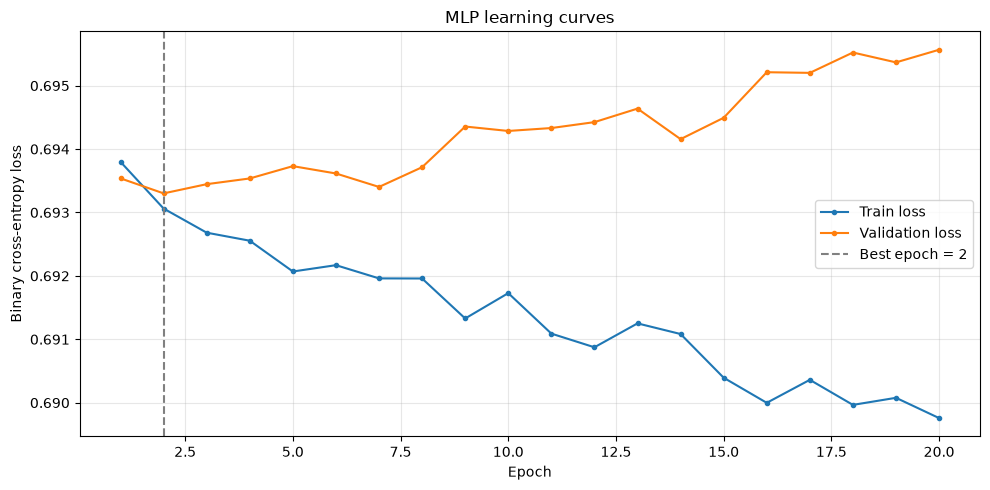

Train loss у найкращу епоху: 0.6931
Validation loss у найкращу епоху: 0.6933
Явних ознак стійкого перенавчання за цим простим критерієм немає; оцініть форму кривих візуально.


In [27]:
plt.figure(figsize=(10,5))
plt.plot(range(1,len(history['train_loss'])+1),history['train_loss'],marker='o',markersize=3,label='Train loss')
plt.plot(range(1,len(history['val_loss'])+1),history['val_loss'],marker='o',markersize=3,label='Validation loss')
plt.axvline(best_epoch,linestyle='--',color='gray',label=f'Best epoch = {best_epoch}')
plt.xlabel('Epoch');plt.ylabel('Binary cross-entropy loss');plt.title('MLP learning curves')
plt.grid(alpha=.3);plt.legend();plt.tight_layout();plt.show()
print('Train loss у найкращу епоху:',round(history['train_loss'][best_epoch-1],4))
print('Validation loss у найкращу епоху:',round(history['val_loss'][best_epoch-1],4))
if best_epoch < len(history['val_loss']) and history['train_loss'][-1]<history['train_loss'][best_epoch-1] and history['val_loss'][-1]>best_val+0.005:
    print('Ознаки перенавчання: train loss зменшується, а validation loss зростає.')
else:
    print('Явних ознак стійкого перенавчання за цим простим критерієм немає; оцініть форму кривих візуально.')

Вісь X показує епохи навчання, вісь Y — середню помилку BCE. Синя лінія (train loss) поступово зменшується, помаранчева (validation loss) після другої епохи загалом зростає. Пунктирна вертикальна лінія позначає найкращу епоху — 2, де validation loss = 0,6933. Спостерігаються ознаки перенавчання, хоча загалом модель навчається слабко.

1.7. Незалежне тестування MLP

Поріг 0,5 перетворює ймовірність sigmoid на клас. Тест оцінюємо лише після вибору найкращої епохи.

MLP test metrics:


,Accuracy,Precision,Recall,F1-macro
MLP (PyTorch),0.496,0.4959,0.4959,0.4955


              precision    recall  f1-score   support

     Missing       0.50      0.53      0.51      6015
  Alert Data       0.49      0.47      0.48      5985

    accuracy                           0.50     12000
   macro avg       0.50      0.50      0.50     12000
weighted avg       0.50      0.50      0.50     12000



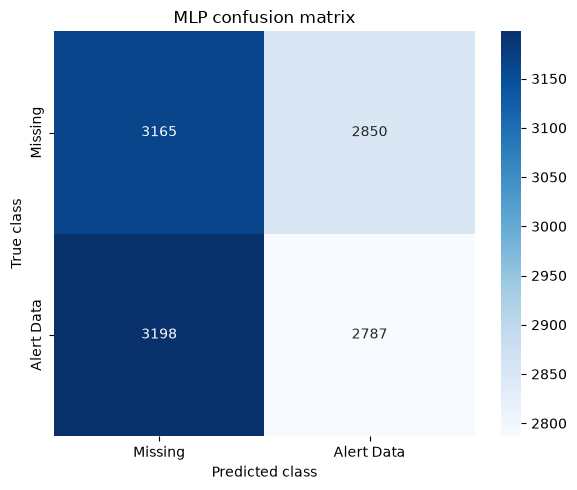

In [28]:
model.eval(); probs=[]
with torch.no_grad():
    for xb,_ in test_loader:
        probs.extend(torch.sigmoid(model(xb.to(device))).cpu().numpy().ravel())
probs=np.asarray(probs)
pred=(probs>=0.5).astype(int)
mlp_metrics={
 'Accuracy':accuracy_score(y_test,pred),
 'Precision':precision_score(y_test,pred,average='macro',zero_division=0),
 'Recall':recall_score(y_test,pred,average='macro',zero_division=0),
 'F1-macro':f1_score(y_test,pred,average='macro',zero_division=0)
}
print('MLP test metrics:');display(pd.DataFrame([mlp_metrics],index=['MLP (PyTorch)']).round(4))
print(classification_report(y_test,pred,target_names=['Missing','Alert Data'],zero_division=0))
cm=confusion_matrix(y_test,pred,labels=[0,1])
plt.figure(figsize=(6,5));sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Missing','Alert Data'],yticklabels=['Missing','Alert Data'])
plt.xlabel('Predicted class');plt.ylabel('True class');plt.title('MLP confusion matrix');plt.tight_layout();plt.show()

Отримано Accuracy = 0,4960 (49,60%), Precision = 0,4959, Recall = 0,4959 та F1-macro = 0,4955. Результати близькі до випадкового вгадування, тому якість класифікації низька.

Правильно класифіковано 3 165 записів Missing і 2 787 записів Alert Data. Помилково визначено 2 850 записів Missing як Alert Data та 3 198 записів Alert Data як Missing. Отже, модель неправильно класифікувала 6 048 із 12 000 записів.

1.8. Порівняння з класичними алгоритмами Lab 1

,Model,Accuracy,Precision,Recall,F1-macro
0,Decision Tree,0.5117,0.5117,0.5117,0.5116
1,kNN,0.5054,0.5054,0.5054,0.5054
2,Random Forest,0.5014,0.5014,0.5014,0.5012
3,AdaBoost,0.4980,0.4982,0.4983,0.4913
4,SVM,0.4966,0.4964,0.4965,0.4955
5,MLP (PyTorch),0.4960,0.4959,0.4959,0.4955


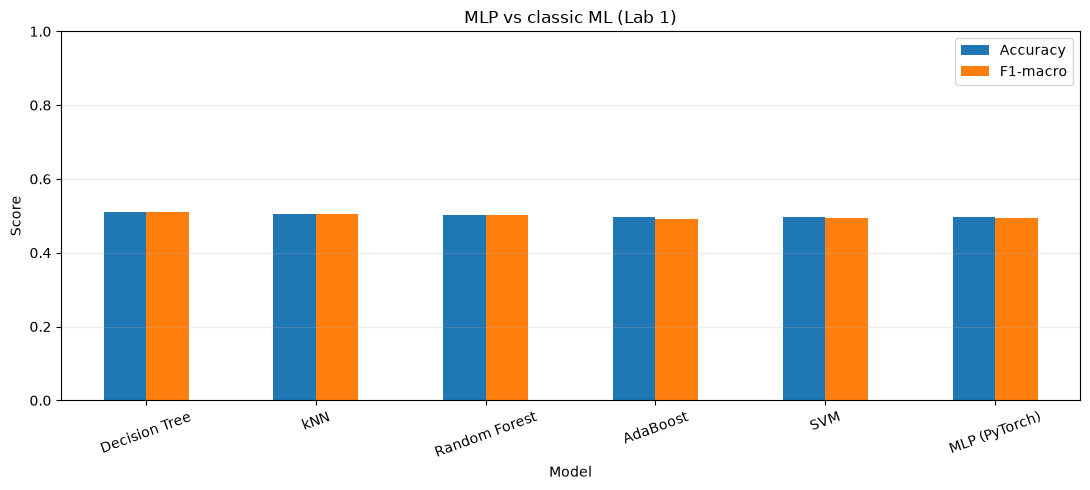

MLP − Decision Tree (Accuracy): -0.0157
MLP − Decision Tree (F1-macro): -0.0161


In [29]:
lab1=pd.DataFrame([
 ['Decision Tree',0.5117,0.5117,0.5117,0.5116],
 ['kNN',0.5054,0.5054,0.5054,0.5054],
 ['Random Forest',0.5014,0.5014,0.5014,0.5012],
 ['SVM',0.4966,0.4964,0.4965,0.4955],
 ['AdaBoost',0.4980,0.4982,0.4983,0.4913]
],columns=['Model','Accuracy','Precision','Recall','F1-macro'])
comparison=pd.concat([lab1,pd.DataFrame([{'Model':'MLP (PyTorch)',**mlp_metrics}])],ignore_index=True)
comparison=comparison.sort_values('Accuracy',ascending=False).reset_index(drop=True)
display(comparison.round(4))
ax=comparison.set_index('Model')[['Accuracy','F1-macro']].plot(kind='bar',figsize=(11,5),rot=20)
ax.set_ylim(0,1);ax.set_ylabel('Score');ax.set_title('MLP vs classic ML (Lab 1)')
ax.grid(axis='y',alpha=.25);plt.tight_layout();plt.show()
print('MLP − Decision Tree (Accuracy):',f"{mlp_metrics['Accuracy']-0.5117:+.4f}")
print('MLP − Decision Tree (F1-macro):',f"{mlp_metrics['F1-macro']-0.5116:+.4f}")

Найкращий результат показала Decision Tree (Accuracy = 0,5117; F1-macro = 0,5116). MLP отримала Accuracy = 0,4960 та F1-macro = 0,4955, поступившись Decision Tree на 1,57 відсоткового пункту за Accuracy. На стовпчиковому графіку вісь X містить назви алгоритмів, вісь Y — значення метрик від 0 до 1; сині стовпчики позначають Accuracy, помаранчеві — F1-macro.

1.9. Автоматизований висновок

In [30]:
gap=history['val_loss'][best_epoch-1]-history['train_loss'][best_epoch-1]
print(f'MLP test Accuracy = {mlp_metrics["Accuracy"]:.4f}, F1-macro = {mlp_metrics["F1-macro"]:.4f}.')
print(f'Найкраща епоха {best_epoch}; train loss = {history["train_loss"][best_epoch-1]:.4f}; validation loss = {best_val:.4f}.')
print(f'Різниця validation − train loss у найкращу епоху = {gap:+.4f}.')
if mlp_metrics['Accuracy']>0.5117:
    print('MLP перевищила історичну Accuracy Decision Tree з Lab 1.')
elif mlp_metrics['Accuracy']<0.5117:
    print('MLP поступилася історичній Accuracy Decision Tree з Lab 1.')
else: print('MLP повторила історичну Accuracy Decision Tree з Lab 1.')
print('Висновок щодо перенавчання зробіть за обома learning curves: одного числового розриву недостатньо.')
print('Класи Missing/Alert Data не слід трактувати як достовірні мітки атаки/нормального трафіку.')

MLP test Accuracy = 0.4960, F1-macro = 0.4955.
Найкраща епоха 2; train loss = 0.6931; validation loss = 0.6933.
Різниця validation − train loss у найкращу епоху = +0.0002.
MLP поступилася історичній Accuracy Decision Tree з Lab 1.
Висновок щодо перенавчання зробіть за обома learning curves: одного числового розриву недостатньо.
Класи Missing/Alert Data не слід трактувати як достовірні мітки атаки/нормального трафіку.


**Загальний висновок:**
У завданні побудовано та навчено повнозв'язану нейронну мережу MLP засобами PyTorch. Аналіз learning curves виявив ознаки перенавчання після другої епохи, а тестування показало низьку якість класифікації (Accuracy 49,60%). Порівняння з п'ятьма класичними алгоритмами продемонструвало, що MLP не перевершила Decision Tree, яка досягла найвищої точності — 51,17%. Отже, використання нейронної мережі не забезпечило покращення результатів на обраному датасеті.

 2. Згорткові нейронні мережі
Оберіть датасет зображень для задачі класифікації. 

Коротко опишіть датасет (класи, кількість зображень) та візуалізуйте приклади зображень для кожного класу. 

Вирішіть задачу класифікації двома способами.
а) Побудуйте просту CNN (2–3 convolutional шари + fully connected layer). Навчіть модель на обраному датасеті.
Побудуйте learning curves (train/validation loss) та проаналізуйте процес навчання.
б) Використайте попередньо натреновану модель (наприклад, ResNet, EfficientNet, MobileNet або іншу pretrained CNN). Замініть вихідний класифікатор відповідно до кількості класів вашого датасету та проведіть донавчання моделі.
Порівняйте CNN, навчену з нуля, та pretrained модель:  якість класифікації;  процес і швидкість збіжності;  learning curves;  вплив обсягу тренувальних даних.
Зробіть висновки.


2.2. Завантаження даних та класи

In [ ]:

DATA_DIR = './data'

raw_train = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split='trainval',
    target_types='binary-category',
    download=True
)

raw_test = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split='test',
    target_types='binary-category',
    download=True
)

labels_train = np.array([
    int(raw_train[i][1]) for i in range(len(raw_train))
])

labels_test = np.array([
    int(raw_test[i][1]) for i in range(len(raw_test))
])

assert set(np.unique(labels_train)) == {0, 1}, \
    'Неочікувані мітки класів у trainval'

assert set(np.unique(labels_test)) == {0, 1}, \
    'Неочікувані мітки класів у test'

CLASS_NAMES = ['Cat', 'Dog']

print('Датасет: Oxford-IIIT Pet')
print('Усього зображень:', len(raw_train) + len(raw_test))
print('Trainval:', len(raw_train))
print('Test:', len(raw_test))

print('\nРозподіл trainval:')
for k in [0, 1]:
    print(f'{CLASS_NAMES[k]}: {(labels_train == k).sum()}')

print('\nРозподіл test:')
for k in [0, 1]:
    print(f'{CLASS_NAMES[k]}: {(labels_test == k).sum()}')


Датасет: Oxford-IIIT Pet
Усього зображень: 7349
Trainval: 3680
Test: 3669

Розподіл trainval:
Cat: 1188
Dog: 2492

Розподіл test:
Cat: 1183
Dog: 2486


Використано Oxford-IIIT Pet, що містить 7 349 зображень двох класів: Cat та Dog. Навчально-тестова частина trainval містить 3 680 зображень, тестова — 3 669. Собаки переважають за кількістю, тому датасет незбалансований.

2.3. Приклади зображень кожного класу

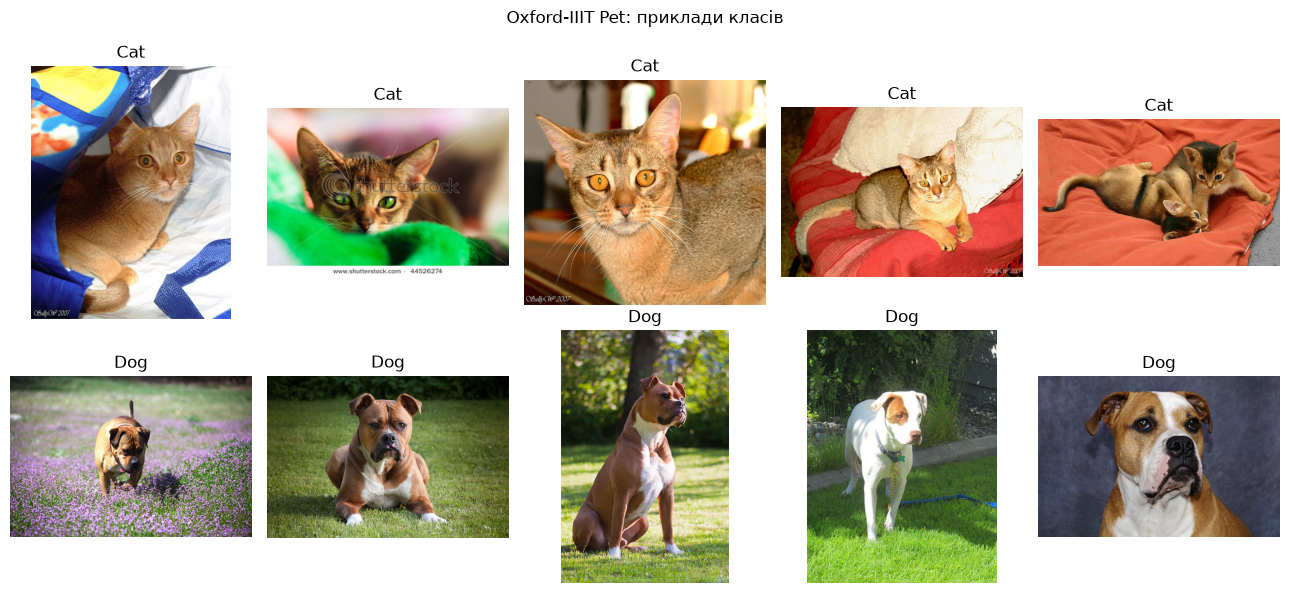

In [40]:

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for row, label in enumerate([0, 1]):
    idxs = np.flatnonzero(labels_train == label)[:5]

    for ax, idx in zip(axes[row], idxs):
        img, _ = raw_train[int(idx)]
        ax.imshow(img)
        ax.set_title(CLASS_NAMES[label])
        ax.axis('off')

plt.suptitle('Oxford-IIIT Pet: приклади класів')
plt.tight_layout()
plt.show()


Представлено по п'ять прикладів кожного класу. Перший рядок містить котів, другий — собак. Зображення відрізняються породами, освітленням, фоном і положенням тварин.

2.4. Передобробка, train/validation/test

Зберігаємо офіційну тестову вибірку окремо. trainval ділимо на 80% train та 20% validation зі стратифікацією. Усі моделі використовують однакові індекси розбиття. Аугментації застосовуються лише до train. Для pretrained MobileNetV3 використовуємо ImageNet-нормалізацію; для коректного порівняння ті самі перетворення використовуємо для простої CNN.

In [ ]:
IMG_SIZE = 160  
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]
train_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
class PetBinary(Dataset):
    def __init__(self, base, transform): self.base, self.transform = base, transform
    def __len__(self): return len(self.base)
    def __getitem__(self, idx):
        img, label = self.base[idx]
        return self.transform(img), int(label)
train_ids, val_ids = train_test_split(np.arange(len(raw_train)), test_size=0.20, stratify=labels_train, random_state=SEED)
train_base = PetBinary(raw_train, train_tf)
val_base = PetBinary(raw_train, eval_tf)
test_set = PetBinary(raw_test, eval_tf)
val_set = Subset(val_base, val_ids.tolist())
BATCH_SIZE = 64
NUM_WORKERS = 0  

def make_loaders(fraction=1.0):
    if fraction < 1.0:
        subset_ids, _ = train_test_split(train_ids, train_size=fraction, stratify=labels_train[train_ids], random_state=SEED)
    else: subset_ids = train_ids
    train_loader = DataLoader(Subset(train_base, list(map(int, subset_ids))), batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader, test_loader
train_loader, val_loader, test_loader = make_loaders()
print('Train:', len(train_ids), 'Validation:', len(val_ids), 'Test:', len(test_set))


Train: 2944 Validation: 736 Test: 3669


Дані розділено на навчальну (2 944 зображення), валідаційну (736) та тестову (3 669) вибірки. Валідаційна використовується для контролю навчання, тестова — для остаточного оцінювання.

2.5. Модель а: проста CNN із трьома згортковими шарами

In [46]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64*4*4, 128), nn.ReLU(),
                                        nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x): return self.classifier(self.features(x))
model_cnn = SimpleCNN().to(device)
print(model_cnn)
print('Параметри:', sum(p.numel() for p in model_cnn.parameters()))


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Параметри: 155042


Побудовано згорткову нейронну мережу з трьома шарами Conv2D (16, 32, 64 фільтри), функціями ReLU, MaxPooling та повнозв'язаним класифікатором. Модель містить 155 042 параметри.

2.6. Модель Б: pretrained MobileNetV3-Small + fine-tuning

Завантажуємо ImageNet-ваги, замінюємо останній Linear на два виходи, заморожуємо більшу частину ознакового екстрактора та розморожуємо останні два блоки. Це донавчання, а не лише навчання нового класифікатора.

In [47]:
def build_pretrained():
    weights = models.MobileNet_V3_Small_Weights.DEFAULT
    net = models.mobilenet_v3_small(weights=weights)
    for p in net.features.parameters(): p.requires_grad = False
    for block in list(net.features.children())[-2:]:
        for p in block.parameters(): p.requires_grad = True
    in_features = net.classifier[-1].in_features
    net.classifier[-1] = nn.Linear(in_features, 2)
    return net.to(device)
model_pretrained = build_pretrained()
print('Навчуваних параметрів:', sum(p.numel() for p in model_pretrained.parameters() if p.requires_grad))


Навчуваних параметрів: 943442


Використано попередньо навчену модель MobileNetV3 із заміненим вихідним класифікатором для двох класів. Для донавчання доступно 943 442 параметри.

2.7. Єдина функція навчання, вимірювання часу та оцінювання

Використовуємо CrossEntropyLoss, оптимізатор Adam, однакові validation/test набори та зберігаємо ваги з найменшим validation loss. Функція не використовує тестові дані під час вибору моделі. accuracy обчислюється за правильними прогнозами.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training and hasattr(model, 'features') and not isinstance(model, SimpleCNN):
        for module in model.features.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm): module.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training: loss.backward(); optimizer.step()
        loss_sum += loss.item()*yb.size(0)
        correct += (logits.argmax(dim=1)==yb).sum().item()
        total += yb.size(0)
    return loss_sum/total, correct/total

def fit_model(model, train_dl, val_dl, epochs=8, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
    best_loss, best_epoch, best_weights = float('inf'), None, None
    start = time.perf_counter()
    for ep in range(1, epochs+1):
        tl, ta = run_epoch(model, train_dl, criterion, optimizer)
        vl, va = run_epoch(model, val_dl, criterion)
        for key, value in [('train_loss',tl),('val_loss',vl),('train_acc',ta),('val_acc',va)]: history[key].append(value)
        if vl < best_loss:
            best_loss, best_epoch = vl, ep
            best_weights = copy.deepcopy(model.state_dict())
        print(f'Epoch {ep}/{epochs} - accuracy: {ta:.4f} - loss: {tl:.4f} - val_accuracy: {va:.4f} - val_loss: {vl:.4f}')
    seconds = time.perf_counter()-start
    model.load_state_dict(best_weights)
    print(f'Найкраща епоха: {best_epoch} | val_loss={best_loss:.4f} | час={seconds:.1f} с')
    return model, history, seconds, best_epoch

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, ps = [], []
    for xb, yb in loader:
        pred = model(xb.to(device)).argmax(dim=1).cpu().numpy()
        ys.extend(yb.numpy().tolist()); ps.extend(pred.tolist())
    return {'Accuracy': accuracy_score(ys, ps), 'F1-macro': f1_score(ys, ps, average='macro')}, np.array(ys), np.array(ps)

def plot_history(histories, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for name, h in histories.items():
        epochs = np.arange(1, len(h['train_loss'])+1)
        ax[0].plot(epochs, h['train_loss'], label=f'{name} train')
        ax[0].plot(epochs, h['val_loss'], '--', label=f'{name} validation')
        ax[1].plot(epochs, h['train_acc'], label=f'{name} train')
        ax[1].plot(epochs, h['val_acc'], '--', label=f'{name} validation')
    ax[0].set(title='Learning curves: loss', xlabel='Epoch', ylabel='Cross-entropy loss')
    ax[1].set(title='Learning curves: accuracy', xlabel='Epoch', ylabel='Accuracy')
    for a in ax: a.grid(alpha=.3); a.legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()


Пункт 2.7 визначає спільний механізм навчання й перевірки обох нейронних мереж.
Він виконує такі операції:
- Forward propagation — обчислює прогнози моделі.
- CrossEntropyLoss — визначає помилку класифікації.
- Backpropagation — обчислює градієнти помилки для оновлення ваг.
- Adam — оптимізує параметри моделі.
- Validation — перевіряє якість після кожної епохи.
- Збереження найкращих ваг — дозволяє використовувати модель із найменшим validation loss.
Призначення: автоматизувати навчання, оцінювання та збереження результатів, щоб Simple CNN і MobileNetV3 порівнювалися за однаковою процедурою.

2.8. Навчання CNN із нуля

Epoch 1/8 - accuracy: 0.6726 - loss: 0.6229 - val_accuracy: 0.6766 - val_loss: 0.6110
Epoch 2/8 - accuracy: 0.6776 - loss: 0.6019 - val_accuracy: 0.6834 - val_loss: 0.5784
Epoch 3/8 - accuracy: 0.6923 - loss: 0.5829 - val_accuracy: 0.6916 - val_loss: 0.5517
Epoch 4/8 - accuracy: 0.7028 - loss: 0.5613 - val_accuracy: 0.7106 - val_loss: 0.5289
Epoch 5/8 - accuracy: 0.7204 - loss: 0.5447 - val_accuracy: 0.7283 - val_loss: 0.5329
Epoch 6/8 - accuracy: 0.7395 - loss: 0.5192 - val_accuracy: 0.7609 - val_loss: 0.4942
Epoch 7/8 - accuracy: 0.7554 - loss: 0.4946 - val_accuracy: 0.7799 - val_loss: 0.4791
Epoch 8/8 - accuracy: 0.7707 - loss: 0.4871 - val_accuracy: 0.7935 - val_loss: 0.4573
Найкраща епоха: 8 | val_loss=0.4573 | час=388.1 с


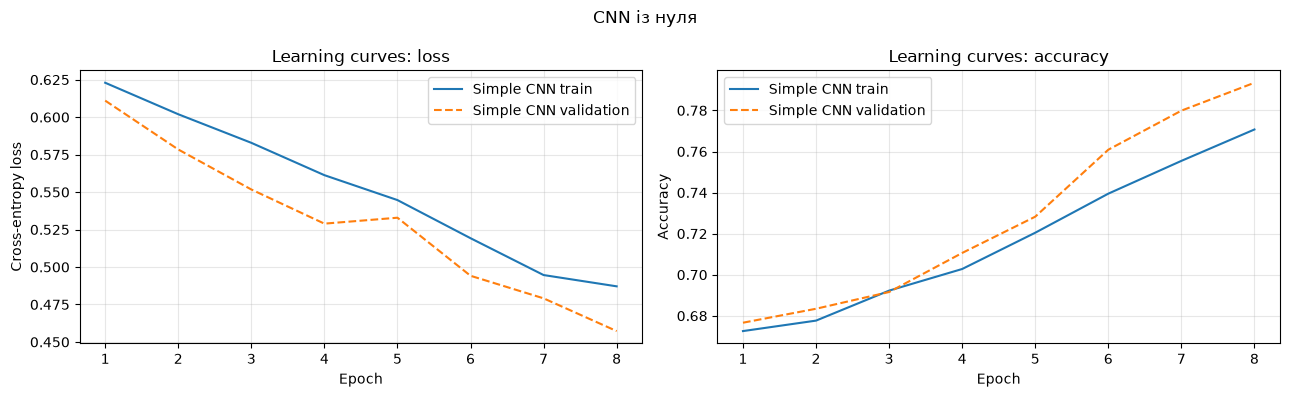

In [49]:
EPOCHS = 8
model_cnn, hist_cnn, sec_cnn, best_cnn = fit_model(model_cnn, train_loader, val_loader, epochs=EPOCHS, lr=1e-3)
plot_history({'Simple CNN':hist_cnn}, 'CNN із нуля')


За 8 епох точність на навчальних даних зросла з 67,26% до 77,07%, а на валідаційних — до 79,35%. Значення validation loss зменшилося до 0,4573. На графіках видно поступове зменшення помилки та зростання точності, без явних ознак перенавчання.

2.9. Донавчання pretrained MobileNetV3-Small

Epoch 1/8 - accuracy: 0.8254 - loss: 0.3511 - val_accuracy: 0.9389 - val_loss: 0.1621
Epoch 2/8 - accuracy: 0.9412 - loss: 0.1386 - val_accuracy: 0.9497 - val_loss: 0.1323
Epoch 3/8 - accuracy: 0.9603 - loss: 0.1047 - val_accuracy: 0.9538 - val_loss: 0.1225
Epoch 4/8 - accuracy: 0.9664 - loss: 0.0816 - val_accuracy: 0.9524 - val_loss: 0.1183
Epoch 5/8 - accuracy: 0.9776 - loss: 0.0624 - val_accuracy: 0.9511 - val_loss: 0.1176
Epoch 6/8 - accuracy: 0.9813 - loss: 0.0513 - val_accuracy: 0.9579 - val_loss: 0.1182
Epoch 7/8 - accuracy: 0.9857 - loss: 0.0421 - val_accuracy: 0.9579 - val_loss: 0.1207
Epoch 8/8 - accuracy: 0.9888 - loss: 0.0320 - val_accuracy: 0.9606 - val_loss: 0.1226
Найкраща епоха: 5 | val_loss=0.1176 | час=242.9 с


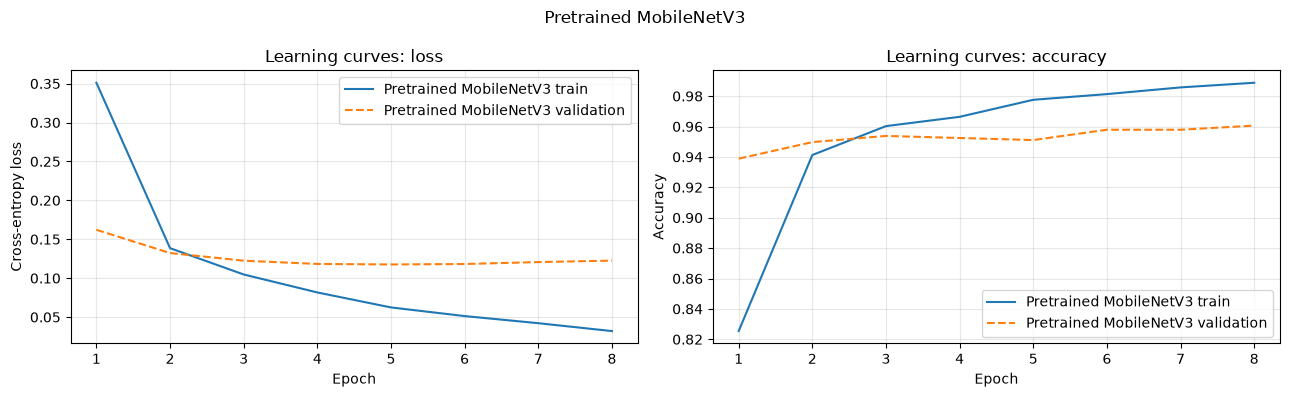

In [50]:
model_pretrained, hist_pre, sec_pre, best_pre = fit_model(model_pretrained, train_loader, val_loader, epochs=EPOCHS, lr=1e-4)
plot_history({'Pretrained MobileNetV3':hist_pre}, 'Pretrained MobileNetV3')


Модель досягла валідаційної точності 96,06% за 8 епох. Найменше значення validation loss = 0,1176 отримано на п'ятій епосі. Після цього тренувальна помилка продовжувала зменшуватися, а валідаційна трохи зростала, що вказує на початкові ознаки перенавчання.

2.10. Порівняння learning curves, швидкості збіжності та тестової якості

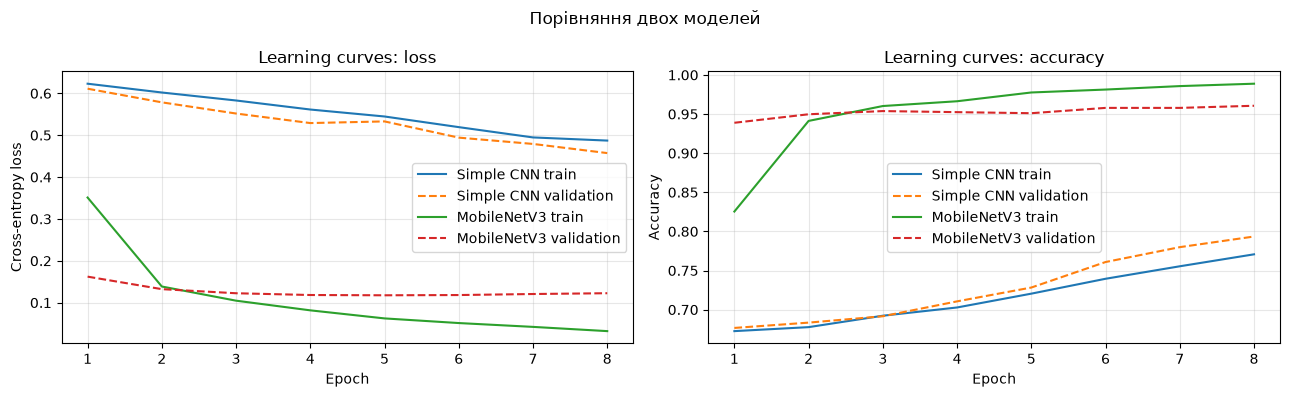

,Модель,Accuracy,F1-macro,Час (с),Найкраща епоха
0,CNN із нуля,0.7866,0.7325,388.0530,8
1,Pretrained MobileNetV3,0.9564,0.9498,242.9434,5


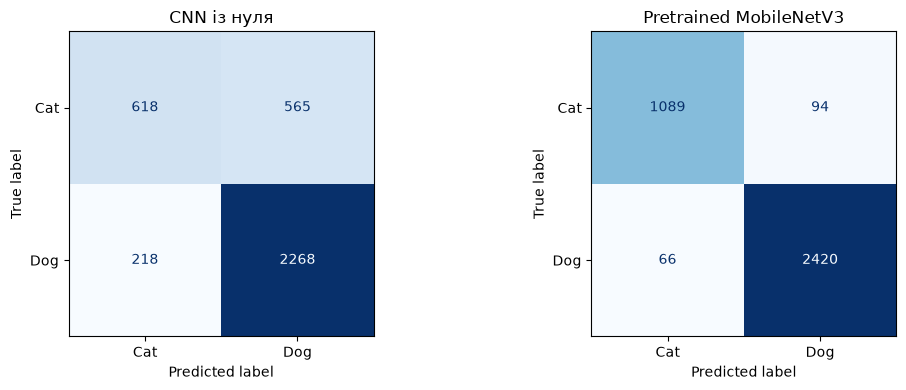

CNN із нуля:
               precision    recall  f1-score   support

         Cat       0.74      0.52      0.61      1183
         Dog       0.80      0.91      0.85      2486

    accuracy                           0.79      3669
   macro avg       0.77      0.72      0.73      3669
weighted avg       0.78      0.79      0.78      3669

Pretrained MobileNetV3:
               precision    recall  f1-score   support

         Cat       0.94      0.92      0.93      1183
         Dog       0.96      0.97      0.97      2486

    accuracy                           0.96      3669
   macro avg       0.95      0.95      0.95      3669
weighted avg       0.96      0.96      0.96      3669



In [51]:
plot_history({'Simple CNN':hist_cnn, 'MobileNetV3':hist_pre}, 'Порівняння двох моделей')
metrics_cnn, y_true, pred_cnn = evaluate(model_cnn, test_loader)
metrics_pre, y_true2, pred_pre = evaluate(model_pretrained, test_loader)
assert np.array_equal(y_true, y_true2)
comparison = pd.DataFrame([
    {'Модель':'CNN із нуля', **metrics_cnn, 'Час (с)':sec_cnn, 'Найкраща епоха':best_cnn},
    {'Модель':'Pretrained MobileNetV3', **metrics_pre, 'Час (с)':sec_pre, 'Найкраща епоха':best_pre}
])
display(comparison.round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, pred, name in zip(axes,[pred_cnn,pred_pre],['CNN із нуля','Pretrained MobileNetV3']):
    ConfusionMatrixDisplay(confusion_matrix(y_true,pred), display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.show()
print('CNN із нуля:\n',classification_report(y_true,pred_cnn,target_names=CLASS_NAMES))
print('Pretrained MobileNetV3:\n',classification_report(y_true,pred_pre,target_names=CLASS_NAMES))


На графіках вісь X позначає епохи, вісь Y — Cross-Entropy Loss або Accuracy. Суцільні лінії відповідають навчанню, пунктирні — валідації. MobileNetV3 швидше досягає високої точності та значно меншої помилки, ніж Simple CNN.
Simple CNN отримала Accuracy 78,66% і F1-macro 0,7325 за 388 секунд, тоді як MobileNetV3 — Accuracy 95,64% і F1-macro 0,9498 за 243 секунди. Отже, pretrained модель точніша на 16,98 відсоткового пункту та швидша в цьому експерименті.
Simple CNN правильно визначила 618 котів і 2 268 собак, припустившись 783 помилок. MobileNetV3 правильно визначила 1 089 котів і 2 420 собак, допустивши лише 160 помилок. Це підтверджує значно кращу здатність pretrained моделі розрізняти класи.
Simple CNN має F1-score 0,61 для котів і 0,85 для собак, тобто гірше розпізнає менш представлений клас котів. MobileNetV3 отримала F1-score 0,93 для котів і 0,97 для собак, забезпечивши високу якість для обох класів.

2.11. Вплив обсягу тренувальних даних (20%, 50%, 100%)

Для кожної частки обидві моделі навчаються заново на однаковій стратифікованій підвибірці. Validation і test залишаються незмінними. Для чесного порівняння використовуються ті самі 8 епох, що й у головному експерименті. Цей блок найдовший за часом.


===== Обсяг train: 20% =====
Epoch 1/8 - accuracy: 0.6769 - loss: 0.6335 - val_accuracy: 0.6766 - val_loss: 0.6278
Epoch 2/8 - accuracy: 0.6769 - loss: 0.6225 - val_accuracy: 0.6766 - val_loss: 0.6194
Epoch 3/8 - accuracy: 0.6769 - loss: 0.6192 - val_accuracy: 0.6766 - val_loss: 0.6151
Epoch 4/8 - accuracy: 0.6786 - loss: 0.6119 - val_accuracy: 0.6766 - val_loss: 0.6221
Epoch 5/8 - accuracy: 0.6786 - loss: 0.6172 - val_accuracy: 0.6766 - val_loss: 0.6166
Epoch 6/8 - accuracy: 0.6769 - loss: 0.6093 - val_accuracy: 0.6766 - val_loss: 0.6050
Epoch 7/8 - accuracy: 0.6684 - loss: 0.5980 - val_accuracy: 0.6780 - val_loss: 0.6031
Epoch 8/8 - accuracy: 0.6820 - loss: 0.5911 - val_accuracy: 0.6834 - val_loss: 0.5956
Найкраща епоха: 8 | val_loss=0.5956 | час=123.2 с
Epoch 1/8 - accuracy: 0.6616 - loss: 0.5908 - val_accuracy: 0.7785 - val_loss: 0.4432
Epoch 2/8 - accuracy: 0.8724 - loss: 0.3444 - val_accuracy: 0.8899 - val_loss: 0.2953
Epoch 3/8 - accuracy: 0.9337 - loss: 0.2222 - val_accuracy: 

,Модель,Частка train,Кількість train,Accuracy,F1-macro,Час (с),Найкраща епоха
0,Simple CNN,0.2,588,0.6841,0.4380,123.1651,8
1,Pretrained MobileNetV3,0.2,588,0.9354,0.9245,90.6593,7
2,Simple CNN,0.5,1472,0.7288,0.6314,223.9595,6
3,Pretrained MobileNetV3,0.5,1472,0.9479,0.9400,142.3494,7
4,Simple CNN,1.0,2944,0.7659,0.7211,388.1615,8
5,Pretrained MobileNetV3,1.0,2944,0.9539,0.9472,234.2022,5


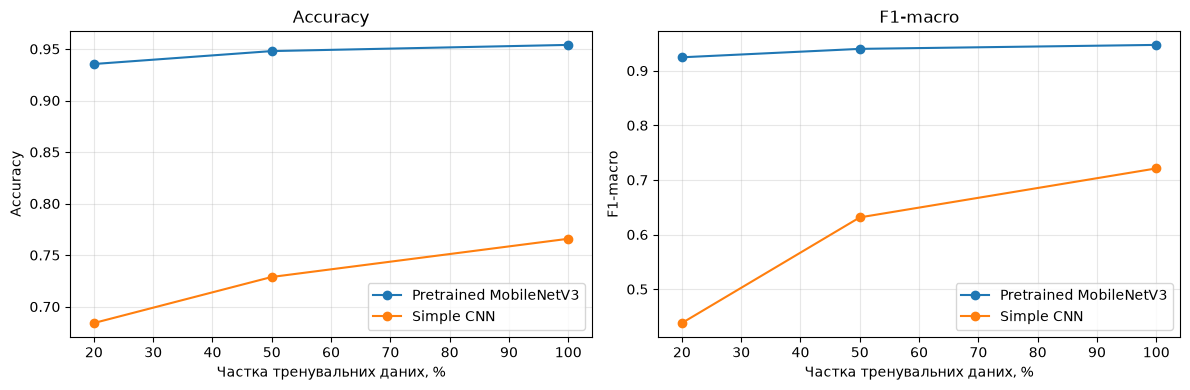

In [ ]:
fractions = [0.2, 0.5, 1.0]
volume_rows = []
for fraction in fractions:
    print(f'\n===== Обсяг train: {fraction:.0%} =====')
    tr, va, te = make_loaders(fraction)
    for name, builder, lr in [
        ('Simple CNN', SimpleCNN, 1e-3),
        ('Pretrained MobileNetV3', build_pretrained, 1e-4)
    ]:
        random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
        model = builder().to(device)
        model, history, seconds, best_epoch = fit_model(model, tr, va, epochs=EPOCHS, lr=lr)
        metric, _, _ = evaluate(model, te)
        volume_rows.append({'Модель':name,'Частка train':fraction,'Кількість train':len(tr.dataset),
                            'Accuracy':metric['Accuracy'],'F1-macro':metric['F1-macro'],
                            'Час (с)':seconds,'Найкраща епоха':best_epoch})
volume_df = pd.DataFrame(volume_rows)
display(volume_df.round(4))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, group in volume_df.groupby('Модель'):
    axes[0].plot(group['Частка train']*100, group['Accuracy'], 'o-', label=name)
    axes[1].plot(group['Частка train']*100, group['F1-macro'], 'o-', label=name)
for ax, title in zip(axes,['Accuracy','F1-macro']):
    ax.set(xlabel='Частка тренувальних даних, %',ylabel=title,title=title)
    ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.show()


Експеримент із 20% даних. При використанні 588 навчальних зображень Simple CNN досягла тестової Accuracy 68,41%, а MobileNetV3 — 93,54%. Навіть на невеликій вибірці pretrained модель демонструє значну перевагу.
Експеримент із 50% даних. На 1 472 зображеннях Simple CNN отримала Accuracy 72,88%, а MobileNetV3 — 94,79%. Збільшення вибірки покращило результати обох моделей.
Експеримент зі 100% даних. На 2 944 зображеннях Simple CNN досягла Accuracy 76,59%, а MobileNetV3 — 95,39%. Найкращий результат знову показала pretrained модель.
Вісь X показує частку навчальних даних (20%, 50%, 100%), вісь Y — Accuracy або F1-macro. Обидві моделі покращують результати зі збільшенням вибірки, проте Simple CNN залежить від кількості даних сильніше. MobileNetV3 забезпечує високу точність навіть за 20% вибірки.

2.12. Автоматичний аналіз та висновки

In [53]:
best = comparison.sort_values('Accuracy', ascending=False).iloc[0]
print('ВИСНОВКИ ЗА ФАКТИЧНИМИ РЕЗУЛЬТАТАМИ')
print(f"1. Найкраща тестова Accuracy: {best['Модель']} — {best['Accuracy']:.4f}.")
print(f"2. CNN із нуля: Accuracy={metrics_cnn['Accuracy']:.4f}, F1-macro={metrics_cnn['F1-macro']:.4f}, час={sec_cnn:.1f} с, найкраща епоха={best_cnn}.")
print(f"3. MobileNetV3: Accuracy={metrics_pre['Accuracy']:.4f}, F1-macro={metrics_pre['F1-macro']:.4f}, час={sec_pre:.1f} с, найкраща епоха={best_pre}.")
for name, h in [('CNN із нуля',hist_cnn),('MobileNetV3',hist_pre)]:
    best_ep = int(np.argmin(h['val_loss']))+1
    delta = h['val_loss'][-1] - h['val_loss'][best_ep-1]
    print(f'4. {name}: мінімум val_loss на епосі {best_ep}; зміна val_loss до кінця {delta:+.4f}.')
print('   Якщо train loss падає, а val loss стійко зростає, це ознака перенавчання; оцініть обидві криві.')
for fraction in fractions:
    part = volume_df[np.isclose(volume_df['Частка train'], fraction)]
    print(f"5. Частка {fraction:.0%}: " + '; '.join(f"{r['Модель']}: accuracy={r['Accuracy']:.4f}" for _,r in part.iterrows()))
print('6. Висновок щодо впливу обсягу даних робіть за трендом на графіку; збільшення даних не гарантує монотонного покращення на кожному запуску.')
print('7. Попередньо навчені ваги можуть прискорювати збіжність і покращувати результат на малих вибірках, але це перевіряється фактичними числами вище.')


ВИСНОВКИ ЗА ФАКТИЧНИМИ РЕЗУЛЬТАТАМИ
1. Найкраща тестова Accuracy: Pretrained MobileNetV3 — 0.9564.
2. CNN із нуля: Accuracy=0.7866, F1-macro=0.7325, час=388.1 с, найкраща епоха=8.
3. MobileNetV3: Accuracy=0.9564, F1-macro=0.9498, час=242.9 с, найкраща епоха=5.
4. CNN із нуля: мінімум val_loss на епосі 8; зміна val_loss до кінця +0.0000.
4. MobileNetV3: мінімум val_loss на епосі 5; зміна val_loss до кінця +0.0049.
   Якщо train loss падає, а val loss стійко зростає, це ознака перенавчання; оцініть обидві криві.
5. Частка 20%: Simple CNN: accuracy=0.6841; Pretrained MobileNetV3: accuracy=0.9354
5. Частка 50%: Simple CNN: accuracy=0.7288; Pretrained MobileNetV3: accuracy=0.9479
5. Частка 100%: Simple CNN: accuracy=0.7659; Pretrained MobileNetV3: accuracy=0.9539
6. Висновок щодо впливу обсягу даних робіть за трендом на графіку; збільшення даних не гарантує монотонного покращення на кожному запуску.
7. Попередньо навчені ваги можуть прискорювати збіжність і покращувати результат на малих ви

**Загальний висновок:**
У завданні реалізовано дві згорткові нейронні мережі засобами PyTorch: Simple CNN, навчену з нуля, та pretrained MobileNetV3. За результатами тестування MobileNetV3 продемонструвала значно вищу точність — 95,64% проти 78,66%, а також швидшу збіжність і меншу кількість помилок. Дослідження впливу обсягу даних показало, що попередньо навчені моделі ефективніше працюють на невеликих вибірках. Отже, transfer learning є ефективнішим підходом для цієї задачі класифікації зображень, оскільки дозволяє використати ознаки, засвоєні під час попереднього навчання.

3. Нейронні мережі для класифікації текстів
Використайте той самий текстовий датасет, з яким ви працювали в лабораторній роботі №2. Проведіть необхідну передобробку текстових даних: токенізацію, побудову словника, перетворення токенів в індекси та приведення послідовностей до однакової довжини (padding/truncation).  Вирішіть задачу класифікації двома способами.
а) Побудуйте модель з Embedding layer, ініціалізованим випадковими вагами. Використайте RNN / LSTM / GRU для класифікації та навчіть модель на своєму датасеті.
б) Завантажте готові pretrained embeddings (наприклад, GloVe) та ініціалізуйте ними Embedding layer. Проведіть навчання моделі.
Для обох моделей побудуйте learning curves (train/validation loss).
Порівняйте результати двох підходів:  якість класифікації;  швидкість і стабільність навчання;  вплив pretrained embeddings на отриманий результат. Зробіть висновки.

3.2. Завантаження SMS Spam Collection

Оригінальний набір UCI містить 5572 повідомлення. Дублікати видаляються до розбиття, щоб не допустити витоку однакових текстів у train/test. Розбиття: 60% train, 20% validation, 20% test.

In [63]:

LOCAL_PATH = 'spam.csv'

df = pd.read_csv(
    LOCAL_PATH,
    encoding='latin-1'
)[['v1', 'v2']]

df.columns = ['label', 'text']

print('До видалення дублікатів:', len(df))
df = df.drop_duplicates(subset=['label', 'text']).reset_index(drop=True)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})
assert df['target'].notna().all()
print('Після видалення дублікатів:', len(df))
print(df['label'].value_counts())
display(df.head())


До видалення дублікатів: 5572
Після видалення дублікатів: 5169
label
ham     4516
spam     653
Name: count, dtype: int64


,label,text,target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


Використано SMS Spam Collection із 5 572 повідомлень. Після видалення 403 дублікатів залишилося 5 169 записів: 4 516 звичайних SMS (ham) та 653 спам-повідомлення (spam). Датасет незбалансований.

3.3. Очищення, токенізація та поділ

Зберігаємо слова й цифри, переводимо в нижній регістр. Словник створюємо лише на train, щоб не використовувати інформацію validation/test. Токени <PAD> та <UNK> мають індекси 0 і 1.

In [64]:
def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+", str(text).lower())

train_df, temp_df = train_test_split(df, test_size=0.4, stratify=df['target'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['target'], random_state=SEED)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_tokens = [tokenize(s) for s in train_df['text']]
counts = Counter(t for sent in train_tokens for t in sent)
MIN_FREQ, MAX_VOCAB, MAX_LEN = 2, 10000, 80
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, count in counts.most_common():
    if count >= MIN_FREQ and len(vocab) < MAX_VOCAB: vocab[word] = len(vocab)
print('Train:', len(train_df), 'Validation:', len(val_df), 'Test:', len(test_df))
print('Розмір словника:', len(vocab), '| Довжина послідовності:', MAX_LEN)
print('Приклад токенів:', train_tokens[0][:20])
print('Приклад індексів:', [vocab.get(w, 1) for w in train_tokens[0][:20]])


Train: 3101 Validation: 1034 Test: 1034
Розмір словника: 2809 | Довжина послідовності: 80
Приклад токенів: ['dont', 'worry', '1', 'day', 'very', 'big', 'lambu', 'ji', 'vl', 'come', 'til', 'then', 'enjoy', 'batchlor', 'party']
Приклад індексів: [113, 510, 46, 69, 190, 319, 1, 1, 962, 62, 511, 60, 278, 1, 711]


Дані розділено на навчальну (3 101), валідаційну (1 034) та тестову (1 034) вибірки. Побудовано словник із 2 809 елементів, виконано токенізацію та перетворення слів в індекси. Довжину послідовностей обмежено 80 токенами.

3.4. Padding/truncation і DataLoader

Кожен текст перетворюється на вектор із 80 індексів: довгі повідомлення обрізаються, короткі доповнюються нулями. Додатково зберігається реальна довжина послідовності для pack_padded_sequence, щоб GRU ігнорувала padding.

In [65]:
class SMSDataset(Dataset):
    def __init__(self, frame):
        self.x, self.lengths, self.y = [], [], []
        for text, target in zip(frame['text'], frame['target']):
            ids = [vocab.get(w, 1) for w in tokenize(text)][:MAX_LEN]
            length = max(1, len(ids))
            ids = (ids + [0] * MAX_LEN)[:MAX_LEN]
            self.x.append(ids); self.lengths.append(length); self.y.append(int(target))
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return (torch.tensor(self.x[i], dtype=torch.long),
                torch.tensor(self.lengths[i], dtype=torch.long),
                torch.tensor(self.y[i], dtype=torch.float32))

BATCH_SIZE = 64
train_loader = DataLoader(SMSDataset(train_df), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SMSDataset(val_df), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SMSDataset(test_df), batch_size=BATCH_SIZE, shuffle=False)
print('Кількість train batch:', len(train_loader))


Кількість train batch: 49


Навчальні дані розділено на 49 пакетів (batches), що дозволяє навчати нейронну мережу поступово, не обробляючи всі повідомлення одночасно.

3.5. Архітектура GRU

Однакова архітектура для обох моделей: Embedding(50) → GRU(64) → Dropout(0.3) → Linear(1). Відмінність лише в ініціалізації embedding. В обох випадках embeddings залишаються trainable для чесного порівняння.

In [66]:
EMBED_DIM = 50
HIDDEN_DIM = 64
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, pretrained_matrix=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBED_DIM, padding_idx=0)
        if pretrained_matrix is not None:
            with torch.no_grad(): self.embedding.weight.copy_(torch.as_tensor(pretrained_matrix, dtype=torch.float32))
        self.gru = nn.GRU(EMBED_DIM, HIDDEN_DIM, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(HIDDEN_DIM, 1)
    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        return self.classifier(self.dropout(hidden[-1])).squeeze(1)

random.seed(SEED); torch.manual_seed(SEED)
random_model = GRUClassifier(len(vocab)).to(DEVICE)
print(random_model)
print('Параметрів:', sum(p.numel() for p in random_model.parameters()))


GRUClassifier(
  (embedding): Embedding(2809, 50, padding_idx=0)
  (gru): GRU(50, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=64, out_features=1, bias=True)
)
Параметрів: 162787


Побудовано рекурентну нейронну мережу з Embedding-шаром розмірності 50, GRU із 64 прихованими нейронами, Dropout 0,3 та вихідним класифікатором. Модель містить 162 787 параметрів.

3.6. Pretrained embeddings GloVe

Завантажуємо glove-wiki-gigaword-50 (50-вимірні англомовні вектори) через gensim.downloader. Невідомі GloVe слова ініціалізуються випадково, <PAD> — нулями. Залежно від середовища перше завантаження може бути тривалим.

In [69]:

print('Завантаження GloVe 50d (може тривати кілька хвилин)...')
glove = api.load('glove-wiki-gigaword-50')
rng = np.random.default_rng(SEED)
glove_matrix = rng.normal(0, 0.05, size=(len(vocab), EMBED_DIM)).astype(np.float32)
glove_matrix[0] = 0.0
found = 0
for word, idx in vocab.items():
    if idx > 1 and word in glove:
        glove_matrix[idx] = glove[word]
        found += 1
print(f'GloVe знайдено для {found}/{max(1, len(vocab)-2)} слів ({found/max(1,len(vocab)-2):.1%})')
torch.manual_seed(SEED)
glove_model = GRUClassifier(len(vocab), pretrained_matrix=glove_matrix).to(DEVICE)
print('Параметрів:', sum(p.numel() for p in glove_model.parameters()))


Завантаження GloVe 50d (може тривати кілька хвилин)...
[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe знайдено для 2540/2807 слів (90.5%)
Параметрів: 162787


Успішно завантажено попередньо навчені вектори GloVe розмірності 50. Вектори знайдено для 2 540 із 2 807 слів (90,5%). Це дозволяє використати вже засвоєні семантичні зв'язки між словами.

3.7. Функції навчання та оцінювання

BCEWithLogitsLoss поєднує sigmoid і BCE у чисельно стійкій реалізації. Adam оновлює ваги. Виводимо показники після кожної епохи; виконуємо рівно 8 епох, але для тесту відновлюємо ваги з найменшим validation loss. Час заміряємо для повного циклу навчання.

In [70]:
EPOCHS = 8

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total = 0.0, 0, 0
    for x, lengths, y in loader:
        x, lengths, y = x.to(DEVICE), lengths.to(DEVICE), y.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(x, lengths)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total_loss += loss.item() * len(y)
        total_correct += ((torch.sigmoid(logits) >= 0.5).float() == y).sum().item()
        total += len(y)
    return total_loss / total, total_correct / total

def train_model(model, name, epochs=EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.BCEWithLogitsLoss()
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_loss, best_epoch, best_state = float('inf'), None, None
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for key, value in [('train_loss', tl), ('train_acc', ta), ('val_loss', vl), ('val_acc', va)]: history[key].append(value)
        if vl < best_loss:
            best_loss, best_epoch, best_state = vl, epoch, copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch}/{epochs} - accuracy: {ta:.4f} - loss: {tl:.4f} - val_accuracy: {va:.4f} - val_loss: {vl:.4f}')
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)
    print(f'{name}: найкраща епоха {best_epoch}, val_loss={best_loss:.4f}, час={elapsed:.1f} с')
    return history, elapsed, best_epoch


Пункт 3.7створює спільний механізм для навчання та перевірки двох GRU-моделей.
Він виконує такі дії:
- Forward propagation — отримує прогноз класу повідомлення.
- Binary Cross-Entropy Loss — обчислює помилку бінарної класифікації.
- Backpropagation — обчислює градієнти для оновлення ваг.
- Adam — оптимізує параметри нейронної мережі.
- Validation — перевіряє якість після кожної епохи.
- Збереження найкращої моделі — зберігає ваги з найменшим validation loss.
- Облік часу та метрик — дозволяє порівняти швидкість і якість навчання.
Призначення: забезпечити однакову процедуру навчання й оцінювання для GRU Random та GRU GloVe, щоб результати їх порівняння були коректними.

3.8. Навчання GRU з випадковими embeddings

In [71]:
torch.manual_seed(SEED)
random_history, random_time, random_best_epoch = train_model(random_model, 'GRU Random')

Epoch 1/8 - accuracy: 0.8384 - loss: 0.4763 - val_accuracy: 0.8752 - val_loss: 0.3374
Epoch 2/8 - accuracy: 0.8926 - loss: 0.2918 - val_accuracy: 0.9284 - val_loss: 0.2052
Epoch 3/8 - accuracy: 0.9442 - loss: 0.1675 - val_accuracy: 0.9545 - val_loss: 0.1308
Epoch 4/8 - accuracy: 0.9742 - loss: 0.0913 - val_accuracy: 0.9632 - val_loss: 0.1117
Epoch 5/8 - accuracy: 0.9855 - loss: 0.0584 - val_accuracy: 0.9720 - val_loss: 0.0870
Epoch 6/8 - accuracy: 0.9923 - loss: 0.0419 - val_accuracy: 0.9729 - val_loss: 0.0888
Epoch 7/8 - accuracy: 0.9932 - loss: 0.0334 - val_accuracy: 0.9671 - val_loss: 0.1046
Epoch 8/8 - accuracy: 0.9948 - loss: 0.0271 - val_accuracy: 0.9729 - val_loss: 0.0930
GRU Random: найкраща епоха 5, val_loss=0.0870, час=17.1 с


За 8 епох тренувальна точність зросла з 83,84% до 99,48%. Найменше значення validation loss = 0,0870 отримано на п'ятій епосі. Після цього валідаційна помилка почала коливатися, що свідчить про початкові ознаки перенавчання.

3.9. Навчання GRU з GloVe embeddings

In [72]:
torch.manual_seed(SEED)
glove_history, glove_time, glove_best_epoch = train_model(glove_model, 'GRU GloVe')

Epoch 1/8 - accuracy: 0.8665 - loss: 0.3591 - val_accuracy: 0.9265 - val_loss: 0.2234
Epoch 2/8 - accuracy: 0.9439 - loss: 0.1585 - val_accuracy: 0.9729 - val_loss: 0.0898
Epoch 3/8 - accuracy: 0.9768 - loss: 0.0759 - val_accuracy: 0.9787 - val_loss: 0.0626
Epoch 4/8 - accuracy: 0.9832 - loss: 0.0601 - val_accuracy: 0.9729 - val_loss: 0.0748
Epoch 5/8 - accuracy: 0.9890 - loss: 0.0441 - val_accuracy: 0.9758 - val_loss: 0.0776
Epoch 6/8 - accuracy: 0.9913 - loss: 0.0381 - val_accuracy: 0.9826 - val_loss: 0.0510
Epoch 7/8 - accuracy: 0.9929 - loss: 0.0293 - val_accuracy: 0.9778 - val_loss: 0.0615
Epoch 8/8 - accuracy: 0.9942 - loss: 0.0254 - val_accuracy: 0.9855 - val_loss: 0.0437
GRU GloVe: найкраща епоха 8, val_loss=0.0437, час=15.4 с


Тренувальна точність зросла з 86,65% до 99,42%, а валідаційна досягла 98,55%. Найкраща епоха — восьма, validation loss = 0,0437. Модель навчалася швидше та досягла меншої помилки.

3.10. Learning curves

Вісь X — епохи; Y — середня BCE. Якщо train loss падає, а validation loss зростає, це ознака перенавчання.

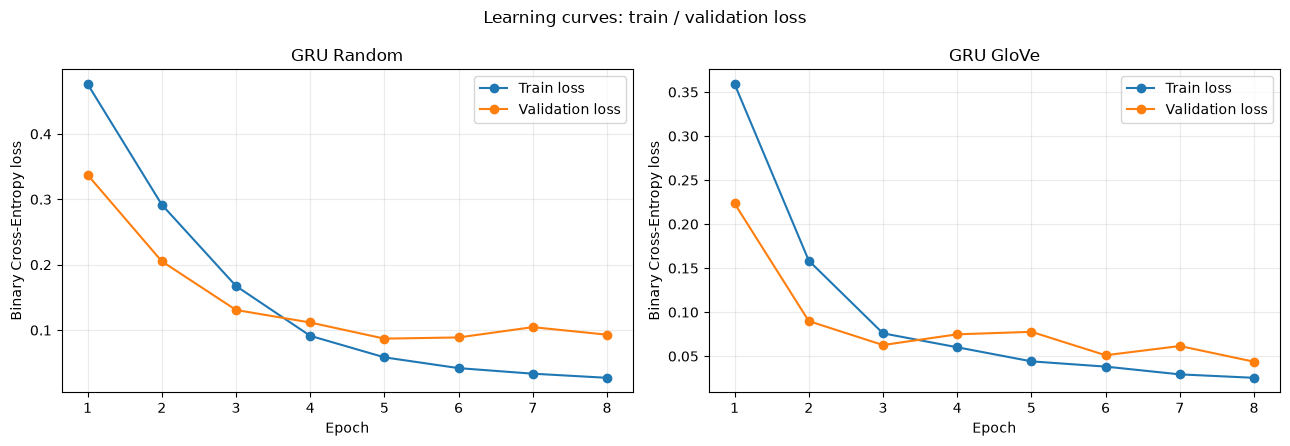

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, hist) in zip(axes, [('GRU Random', random_history), ('GRU GloVe', glove_history)]):
    epochs = np.arange(1, len(hist['train_loss'])+1)
    ax.plot(epochs, hist['train_loss'], marker='o', label='Train loss')
    ax.plot(epochs, hist['val_loss'], marker='o', label='Validation loss')
    ax.set(title=name, xlabel='Epoch', ylabel='Binary Cross-Entropy loss')
    ax.grid(alpha=.25); ax.legend()
plt.suptitle('Learning curves: train / validation loss')
plt.tight_layout(); plt.show()


На графіках вісь X показує епохи, вісь Y — Binary Cross-Entropy Loss (помилку бінарної класифікації). Синя лінія відповідає тренувальній помилці, помаранчева — валідаційній. Обидві моделі навчаються успішно, але GRU GloVe має меншу валідаційну помилку та стабільнішу збіжність наприкінці навчання.

3.11. Тестові метрики та матриці помилок

Тестовий набір використовується лише після вибору найкращої епохи за validation. Для нерівномірних класів аналізуємо F1 для spam та Recall для spam разом із Accuracy та F1-macro.


GRU Random
               precision    recall  f1-score   support

         ham       0.98      0.99      0.99       904
        spam       0.94      0.86      0.90       130

    accuracy                           0.98      1034
   macro avg       0.96      0.93      0.94      1034
weighted avg       0.98      0.98      0.98      1034


GRU GloVe
               precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       0.99      0.88      0.93       130

    accuracy                           0.98      1034
   macro avg       0.99      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



,Модель,Accuracy,F1-macro,Precision spam,Recall spam,F1 spam,Час (с),Найкраща епоха
0,GRU Random,0.9758,0.9429,0.9412,0.8615,0.8996,17.0701,5
1,GRU GloVe,0.9845,0.9631,0.9914,0.8846,0.9350,15.4359,8


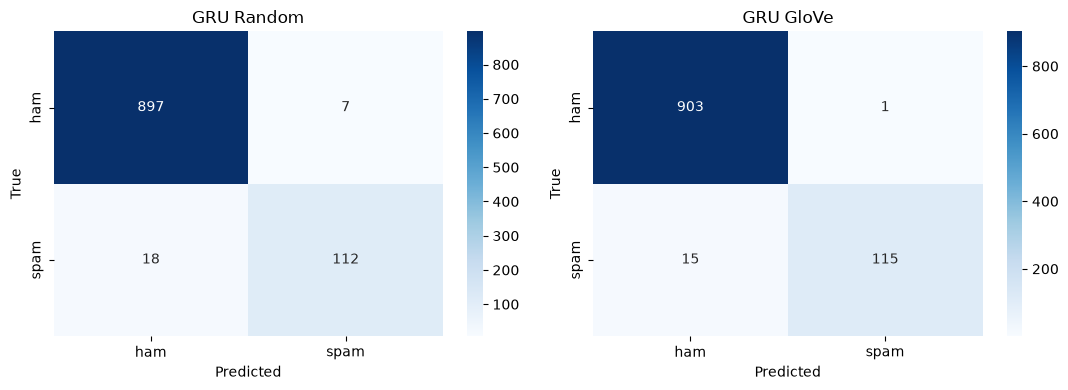

In [74]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    yt, yp = [], []
    for x, lengths, y in loader:
        logits = model(x.to(DEVICE), lengths.to(DEVICE))
        yp.extend((torch.sigmoid(logits).cpu().numpy() >= 0.5).astype(int))
        yt.extend(y.numpy().astype(int))
    return np.array(yt), np.array(yp)

rows = []; predictions = {}
for name, model, seconds, best_ep in [
    ('GRU Random', random_model, random_time, random_best_epoch),
    ('GRU GloVe', glove_model, glove_time, glove_best_epoch)]:
    y_true, y_pred = evaluate(model, test_loader)
    predictions[name] = (y_true, y_pred)
    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    p_spam, r_spam, f_spam, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', pos_label=1, zero_division=0)
    rows.append({'Модель': name, 'Accuracy': accuracy_score(y_true, y_pred), 'F1-macro': f_macro,
                 'Precision spam': p_spam, 'Recall spam': r_spam, 'F1 spam': f_spam,
                 'Час (с)': seconds, 'Найкраща епоха': best_ep})
    print(f'\n{name}\n', classification_report(y_true, y_pred, target_names=['ham', 'spam'], zero_division=0))
results = pd.DataFrame(rows)
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, (yt, yp)) in zip(axes, predictions.items()):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues',
                xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'], ax=ax)
    ax.set(title=name, xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.show()


GRU Random отримала F1-score 0,90 для спаму, а GRU GloVe — 0,93. Отже, pretrained embeddings покращили якість розпізнавання небажаних повідомлень.
GRU Random правильно визначила 897 звичайних повідомлень і 112 спам-повідомлень, допустивши 25 помилок. GRU GloVe правильно визначила 903 звичайні повідомлення і 115 спам-повідомлень, допустивши лише 16 помилок. Таким чином, використання GloVe зменшило кількість помилок на 9.

3.12. Порівняння якості, швидкості та стабільності

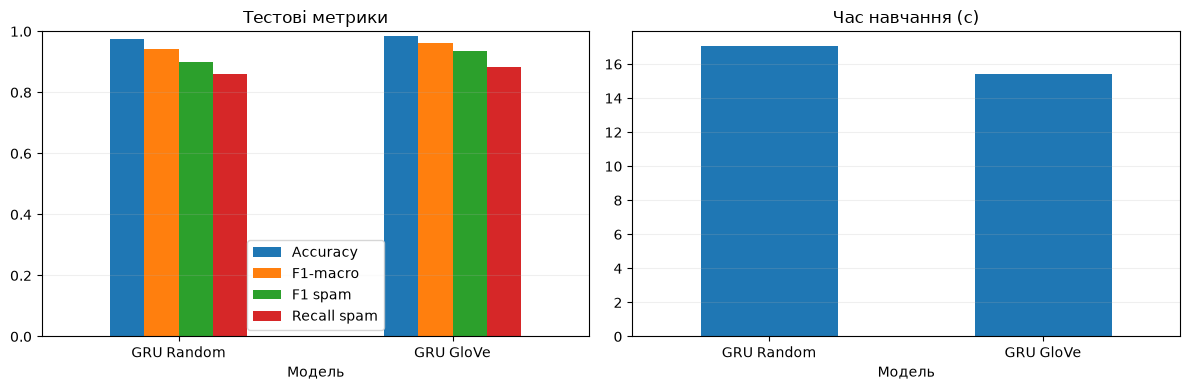

GRU Random: min val_loss=0.0870 (епоха 5), останній val_loss=0.0930, std(val_loss)=0.0813
GRU GloVe: min val_loss=0.0437 (епоха 8), останній val_loss=0.0437, std(val_loss)=0.0539


In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results.set_index('Модель')[['Accuracy', 'F1-macro', 'F1 spam', 'Recall spam']].plot.bar(ax=axes[0], rot=0, ylim=(0, 1), title='Тестові метрики')
results.set_index('Модель')['Час (с)'].plot.bar(ax=axes[1], rot=0, title='Час навчання (с)')
axes[0].grid(axis='y', alpha=.2); axes[1].grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()
for name, hist in [('GRU Random', random_history), ('GRU GloVe', glove_history)]:
    vals = np.array(hist['val_loss'])
    print(f'{name}: min val_loss={vals.min():.4f} (епоха {vals.argmin()+1}), '
          f'останній val_loss={vals[-1]:.4f}, std(val_loss)={vals.std():.4f}')


Лівий графік демонструє перевагу GRU GloVe за Accuracy, F1-macro, F1 spam та Recall spam. Правий показує час навчання: GRU GloVe навчалася приблизно на 1,63 секунди швидше.
Для GRU Random мінімальна валідаційна помилка становила 0,0870, а стандартне відхилення — 0,0813. Для GRU GloVe відповідні значення становили 0,0437 та 0,0539. Менше стандартне відхилення свідчить про нижчу загальну мінливість валідаційної помилки, хоча обидві моделі мають коливання.

3.13. Автоматизований висновок

In [76]:
r = results.set_index('Модель')
a, b = r.loc['GRU Random'], r.loc['GRU GloVe']
print('ВИСНОВОК ДО ЗАВДАННЯ 3')
print(f"GRU із випадковими embeddings: Accuracy={a['Accuracy']:.4f}, F1-macro={a['F1-macro']:.4f}, "
      f"F1(spam)={a['F1 spam']:.4f}, Recall(spam)={a['Recall spam']:.4f}, час={a['Час (с)']:.1f} с.")
print(f"GRU із GloVe: Accuracy={b['Accuracy']:.4f}, F1-macro={b['F1-macro']:.4f}, "
      f"F1(spam)={b['F1 spam']:.4f}, Recall(spam)={b['Recall spam']:.4f}, час={b['Час (с)']:.1f} с.")
print(f"Різниця GloVe - Random: Accuracy={b['Accuracy']-a['Accuracy']:+.4f}, "
      f"F1(spam)={b['F1 spam']-a['F1 spam']:+.4f}.")
print('За цими даними попередньо навчені embeddings ' +
      ('покращили' if b['F1 spam'] > a['F1 spam'] else 'не покращили') +
      ' F1 для spam порівняно з випадковою ініціалізацією.')
for name, hist in [('Random', random_history), ('GloVe', glove_history)]:
    best = int(np.argmin(hist['val_loss']))
    gap = hist['val_loss'][-1] - hist['val_loss'][best]
    print(f'{name}: найкращий val_loss на епосі {best+1}; подальша зміна до останньої епохи: {gap:+.4f}.')
print('Зверніть увагу: 8 епох — навчальний експеримент; висновок про перевагу GloVe стосується саме цього запуску.')


ВИСНОВОК ДО ЗАВДАННЯ 3
GRU із випадковими embeddings: Accuracy=0.9758, F1-macro=0.9429, F1(spam)=0.8996, Recall(spam)=0.8615, час=17.1 с.
GRU із GloVe: Accuracy=0.9845, F1-macro=0.9631, F1(spam)=0.9350, Recall(spam)=0.8846, час=15.4 с.
Різниця GloVe - Random: Accuracy=+0.0087, F1(spam)=+0.0354.
За цими даними попередньо навчені embeddings покращили F1 для spam порівняно з випадковою ініціалізацією.
Random: найкращий val_loss на епосі 5; подальша зміна до останньої епохи: +0.0060.
GloVe: найкращий val_loss на епосі 8; подальша зміна до останньої епохи: +0.0000.
Зверніть увагу: 8 епох — навчальний експеримент; висновок про перевагу GloVe стосується саме цього запуску.


**Загальний висновок:**
У завданні реалізовано дві рекурентні нейронні мережі GRU для класифікації SMS-повідомлень. Використання попередньо навчених GloVe embeddings покращило Accuracy з 97,58% до 98,45%, F1-macro з 0,9429 до 0,9631, а F1 для спаму з 0,8996 до 0,9350. Крім того, GRU GloVe продемонструвала швидшу збіжність на початкових епохах, меншу валідаційну помилку та трохи коротший час навчання. Отже, для цього датасету використання pretrained embeddings виявилося ефективнішим за випадкову ініціалізацію векторів слів.

**Загальний висновок до лабораторної роботи:**
У ході лабораторної роботи було досліджено основні підходи до побудови, навчання та оцінювання нейронних мереж для різних типів даних: табличних, зображень і текстів. Для реалізації моделей використано бібліотеку PyTorch. Проведено передобробку даних, навчання моделей, оцінювання їхньої якості за метриками Accuracy, Precision, Recall та F1-score, а також аналіз процесу навчання за графіками train/validation loss.

У першому завданні реалізовано повнозв'язану нейронну мережу MLP для класифікації мережевих подій. Модель досягла точності 49,60%, що виявилося нижчим за результат Decision Tree (51,17%) із лабораторної роботи №1. Аналіз learning curves показав ознаки перенавчання: тренувальна помилка зменшувалася, тоді як валідаційна поступово зростала. Отримані результати свідчать, що використання нейронних мереж не завжди забезпечує перевагу над класичними алгоритмами машинного навчання, особливо за недостатньої інформативності ознак.

У другому завданні побудовано просту згорткову нейронну мережу CNN та використано попередньо навчену MobileNetV3 для класифікації зображень котів і собак із датасету Oxford-IIIT Pet. Проста CNN досягла точності 78,66%, тоді як MobileNetV3 — 95,64%. Попередньо навчена модель продемонструвала швидшу збіжність, меншу кількість помилок і кращу якість класифікації навіть за обмеженого обсягу тренувальних даних. Це підтвердило ефективність transfer learning для задач комп'ютерного зору.

У третьому завданні реалізовано дві рекурентні нейронні мережі GRU для класифікації SMS-повідомлень: із випадковою ініціалізацією Embedding та з попередньо навченими векторами GloVe. Перша модель досягла точності 97,58%, друга — 98,45%. Використання GloVe забезпечило кращі показники F1-score, швидшу збіжність і зменшення кількості помилок класифікації. Це продемонструвало переваги використання попередньо навчених векторних представлень слів для обробки текстових даних.

Отже, мету лабораторної роботи досягнуто. Дослідження показало, що ефективність нейронних мереж залежить від типу даних, архітектури моделі, якості передобробки та способу ініціалізації параметрів. Найбільші переваги нейромережевих підходів у проведених експериментах спостерігалися під час використання попередньо навчених моделей і векторних представлень. Водночас результати MLP підтвердили необхідність порівнювати нейронні мережі з класичними алгоритмами та контролювати перенавчання за допомогою валідаційних метрик.